# 07 Maps

Two maps of the Slantsy catchment from notebook 06 (base scenario, central distance decay):

1. a static hero map for the README (`figures/07_hero_map.png`);
2. an interactive map for GitHub Pages (`docs/klint_visitor_map.html`).

The new complex does not have its own point yet. As in 06, it sits at the existing Slantsy museum: both are in the town centre on the Plyussa riverfront, a few minutes apart by car. Colours: violet for the model, orange only for Slantsy.

In [9]:
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter, binary_fill_holes
from scipy.spatial import cKDTree

CRS = 32636
NEW_SITE_PROXY = "Slantsy Local History Museum"  # new complex placed at the existing museum

MAIN, MID, LIGHT = "#6a51a3", "#756bb1", "#bcbddc"
PURPLES = ["#f2f0f7", "#cbc9e2", "#9e9ac8", "#756bb1", "#54278f"]
ORANGE, DARK = "#FF9354", "#333333"
GREY, LIGHT_GREY, DARK_GREY = "#999999", "#d9d9d9", "#555555"
HALO = [pe.withStroke(linewidth=3, foreground="white")]

study = gpd.read_file("../data/processed/study_area.geojson").to_crs(CRS)
catch = pd.read_csv("../data/processed/catchment_slantsy.csv")
geo = pd.read_csv("../data/processed/attractions_geo.csv")
attr = pd.read_csv("../data/attractions.csv")
sites = pd.read_csv("../data/processed/calibration_sites.csv")

# role from attractions.csv: the one in attractions_geo.csv predates the Sablino change
attractions = (geo.drop(columns="role")
                  .merge(attr[["name_en", "role"]], on="name_en", how="left")
                  .merge(sites[["name_en", "visitors", "year", "factor_C"]], on="name_en", how="left"))
attractions = gpd.GeoDataFrame(
    attractions, geometry=gpd.points_from_xy(attractions.lon, attractions.lat), crs=4326
).to_crs(CRS)
assert attractions["role"].notna().all(), "role missing for some attraction"
assert NEW_SITE_PROXY in set(attractions["name_en"])

print(f"{len(catch):,} origins, {catch['visits'].sum():,.0f} visits a year (base scenario)")
print(attractions.groupby("role").size())

3,440 origins, 36,015 visits a year (base scenario)
role
calibration    8
competitor     2
context        3
dtype: int64


## Static hero map

Bands show car travel time to Slantsy. Travel times of the 3,440 origins are put onto a 1 km grid and lightly smoothed, so band edges are approximate (a few km). Areas more than 6 km from any populated cell (the Gulf of Finland, Lake Ladoga, large empty swamps) are left white. The legend gives the share of modelled day-trip visits (base scenario) that comes from each band. Model sites are sized by annual attendance. The existing Slantsy museum is one of them, hidden under the orange marker for the new complex.

band
under 1 h    0.131
1-2 h        0.101
2-3 h        0.325
3-4 h        0.427
over 4 h     0.015
Name: visits, dtype: float64


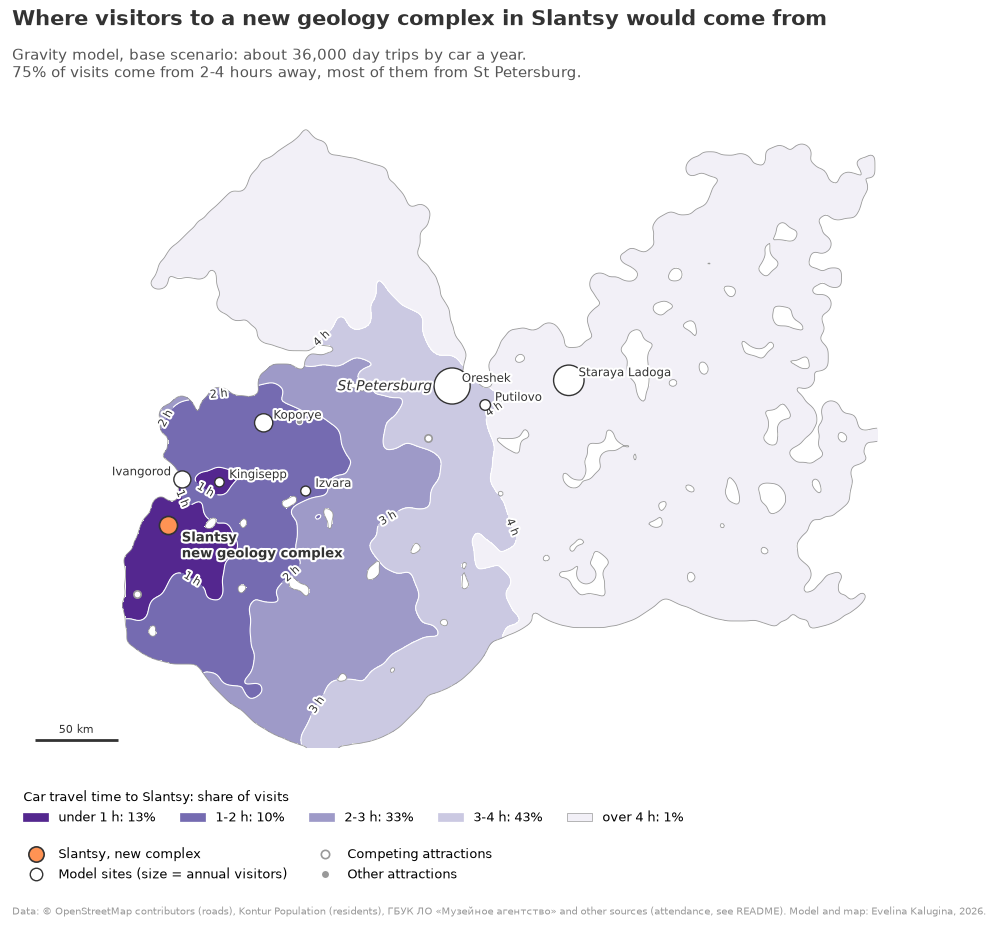

In [8]:
BANDS = [0, 60, 120, 180, 240, 10_000]
BAND_NAMES = ["under 1 h", "1-2 h", "2-3 h", "3-4 h", "over 4 h"]
BAND_COLORS = PURPLES[::-1]  # dark = close to Slantsy

catch["band"] = pd.cut(catch["time_min"], BANDS, labels=BAND_NAMES, right=False)
total = catch["visits"].sum()
share = catch.groupby("band", observed=False)["visits"].sum() / total
print(share.round(3))

# travel time on a 1 km grid, smoothed
xmin, ymin, xmax, ymax = study.total_bounds
STEP = 1_000
gx, gy = np.meshgrid(np.arange(xmin, xmax, STEP), np.arange(ymin, ymax, STEP))
pts = catch[["x", "y"]].to_numpy()
tt = griddata(pts, catch["time_min"], (gx, gy), method="linear")
tt = np.where(np.isnan(tt), griddata(pts, catch["time_min"], (gx, gy), method="nearest"), tt)
tt = gaussian_filter(tt, sigma=3)

# keep only land near populated cells: drops the gulf, Ladoga and empty swamps
dist, _ = cKDTree(pts).query(np.c_[gx.ravel(), gy.ravel()])
populated = (dist.reshape(gx.shape) <= 6_000) & shapely.contains_xy(study.union_all(), gx, gy)
land = gaussian_filter(populated.astype(float), sigma=2)
tt = np.ma.masked_where(land < 0.5, tt)

fig, ax = plt.subplots(figsize=(10, 9.5))
fig.subplots_adjust(left=0.03, right=0.97, top=0.86, bottom=0.17)

ax.contourf(gx, gy, tt, levels=BANDS, colors=BAND_COLORS, zorder=1)
cs = ax.contour(gx, gy, tt, levels=BANDS[1:-1], colors="white", linewidths=0.8, zorder=2)
for txt in ax.clabel(cs, fmt=lambda v: f"{v / 60:.0f} h", fontsize=8, inline=True):
    txt.set_color(DARK)
    txt.set_path_effects(HALO)
ax.contour(gx, gy, land, levels=[0.5], colors=GREY, linewidths=0.6, zorder=3)

others = attractions[attractions["name_en"] != NEW_SITE_PROXY]
ctx = others[others["role"] == "context"]
ax.scatter(ctx.geometry.x, ctx.geometry.y, s=22, color=GREY, edgecolor="white", linewidth=0.8, zorder=4)
comp = others[others["role"] == "competitor"]
ax.scatter(comp.geometry.x, comp.geometry.y, s=28, color="white", edgecolor=GREY, linewidth=1.2, zorder=5)
cal = others[others["role"] == "calibration"].sort_values("visitors", ascending=False)
ax.scatter(cal.geometry.x, cal.geometry.y, s=15 + cal["visitors"] / 300, color="white",
           edgecolor=DARK, linewidth=1, zorder=6)

KEYS = ["Oreshek", "Staraya Ladoga", "Koporye", "Ivangorod", "Kingisepp", "Izvara", "Putilovo"]
OFFSETS = {"Ivangorod": (-7, 3, "right"), "Kingisepp": (7, 3, "left")}
for _, r in cal.iterrows():
    key = next((k for k in KEYS if k.lower() in r["name_en"].lower()), None)
    if key is None:
        print("no label for:", r["name_en"])
        continue
    dx, dy, ha = OFFSETS.get(key, (7, 3, "left"))
    ax.annotate(key, (r.geometry.x, r.geometry.y), xytext=(dx, dy), textcoords="offset points",
                fontsize=8.5, color=DARK, ha=ha, path_effects=HALO, zorder=7)

spb = gpd.GeoSeries(gpd.points_from_xy([30.315], [59.939]), crs=4326).to_crs(CRS).iloc[0]
ax.text(spb.x, spb.y, "St Petersburg", fontsize=10, style="italic", color=DARK,
        ha="center", va="center", path_effects=HALO, zorder=7)

sl = attractions.loc[attractions["name_en"] == NEW_SITE_PROXY].geometry.iloc[0]
ax.scatter(sl.x, sl.y, s=170, color=ORANGE, edgecolor=DARK, linewidth=1.2, zorder=8)
ax.annotate("Slantsy\nnew geology complex", (sl.x, sl.y), xytext=(10, -4), textcoords="offset points",
            fontsize=9.5, fontweight="bold", color=DARK, va="top", path_effects=HALO, zorder=9)

ax.set_xlim(xmin - 10_000, xmax + 10_000)
ax.set_ylim(ymin - 10_000, ymax + 10_000)
ax.set_aspect("equal")
ax.set_axis_off()
x0, y0 = xmin + 5_000, ymin + 5_000
ax.plot([x0, x0 + 50_000], [y0, y0], color=DARK, linewidth=2, solid_capstyle="butt")
ax.text(x0 + 25_000, y0 + 4_000, "50 km", ha="center", fontsize=8, color=DARK)

fig.text(0.06, 0.965, "Where visitors to a new geology complex in Slantsy would come from",
         fontsize=15, fontweight="bold", color=DARK, ha="left", va="top")
fig.text(0.06, 0.925,
         f"Gravity model, base scenario: about {round(total, -3):,.0f} day trips by car a year.\n"
         f"{share['2-3 h'] + share['3-4 h']:.0%} of visits come from 2-4 hours away, "
         "most of them from St Petersburg.",
         fontsize=10.5, color=DARK_GREY, ha="left", va="top")

band_handles = [Patch(facecolor=c, edgecolor=GREY if i == len(BAND_COLORS) - 1 else c,
                      linewidth=0.5, label=f"{n}: {share[n]:.0%}")
                for i, (c, n) in enumerate(zip(BAND_COLORS, BAND_NAMES))]
fig.legend(handles=band_handles, title="Car travel time to Slantsy: share of visits",
           loc="lower left", bbox_to_anchor=(0.06, 0.095), ncol=5, frameon=False,
           fontsize=9, title_fontsize=9, alignment="left")

site_handles = [
    Line2D([0], [0], marker="o", ls="", markersize=11, markerfacecolor=ORANGE,
           markeredgecolor=DARK, markeredgewidth=1.2, label="Slantsy, new complex"),
    Line2D([0], [0], marker="o", ls="", markersize=9, markerfacecolor="white",
           markeredgecolor=DARK, label="Model sites (size = annual visitors)"),
    Line2D([0], [0], marker="o", ls="", markersize=6, markerfacecolor="white",
           markeredgecolor=GREY, markeredgewidth=1.2, label="Competing attractions"),
    Line2D([0], [0], marker="o", ls="", markersize=6, markerfacecolor=GREY,
           markeredgecolor="white", label="Other attractions"),
]
fig.legend(handles=site_handles, loc="lower left", bbox_to_anchor=(0.06, 0.035), ncol=2,
           frameon=False, fontsize=9)

fig.text(0.06, 0.012,
         "Data: © OpenStreetMap contributors (roads), Kontur Population (residents), "
         "ГБУК ЛО «Музейное агентство» and other sources (attendance, see README). "
         "Model and map: Evelina Kalugina, 2026.",
         fontsize=7.5, color=GREY, ha="left")

fig.savefig("../figures/07_hero_map.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()